# 05 - XGBoost the a Predict Model

## objective 



In [63]:
from pathlib import Path
import pandas as pd

# Caminho of the projeto
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "interm"

# Carregamento of the date
csv_file = DATA_PATH / "data_3.csv"
banco = pd.read_csv(csv_file)

In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor

In [65]:
# Parâmetros of estilo of the Gráfico based in the manual of the MBA
plt.rcParams.update({

    # font
    "font.family": "Arial",
    "font.size": 11,

    # background
    "figure.facecolor": "white",
    "axes.facecolor": "white",

    # without grid
    "axes.grid": False,

    # without title
    "axes.titlesize": 0,

    # axes
    "axes.edgecolor": "black",
    "axes.linewidth": 1.5,

    # color of the textos
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    # size of the titles of the axes
    "axes.labelsize": 11

})

In [66]:
def plot_with_style(
    data,
    kind='line',                 # 'line' or 'bar'
    x_label='',
    y_label='',
    title='',
    xticks=None,                 # ticks personalizados
    xtlabels=None,               # labels personalizados
    rotate_xticks=0,
    figsize=(12, 6),
    marker='o',
    linewidth=2,
    colors=None,
    linestyles=None,
    xlim=None,                   # ex.: ('2017-01-01', '2026-01-01')
    year_ticks=True,             # ticks annual automáticos
    vline=None,                  # ex.: test.index[0]
    vline_label=None
):

    # ---------------------------------------------------------
    # Validação
    # ---------------------------------------------------------

    if not isinstance(data, (pd.Series, pd.DataFrame)):
        raise ValueError(
            'date must be pd.Series or pd.DataFrame'
        )

    if kind not in ['line', 'bar']:
        raise ValueError(
            "kind must be 'line' or 'bar'"
        )

    # ---------------------------------------------------------
    # creation of the figura
    # ---------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    # ---------------------------------------------------------
    # Gráfico of Series
    # ---------------------------------------------------------

    if isinstance(data, pd.Series):

        label = data.name if data.name is not None else 'Série'

        if kind == 'line':

            ax.plot(
                data.index,
                data.values,
                marker=marker,
                linewidth=linewidth,
                label=label
            )

        else:

            ax.bar(
                data.index,
                data.values,
                edgecolor='black',
                linewidth=0.8,
                label=label
            )

    # ---------------------------------------------------------
    # Gráfico of DataFrame
    # ---------------------------------------------------------

    elif isinstance(data, pd.DataFrame):

        if kind == 'line':

            for i, column in enumerate(data.columns):

                kwargs = {
                    'marker': marker,
                    'linewidth': linewidth,
                    'label': column
                }

                if colors is not None:
                    kwargs['color'] = colors[i]

                if linestyles is not None:
                    kwargs['linestyle'] = linestyles[i]

                ax.plot(
                    data.index,
                    data[column],
                    **kwargs
                )

        else:

            data.plot(
                kind='bar',
                ax=ax
            )

    # ---------------------------------------------------------
    # labels
    # ---------------------------------------------------------

    ax.set_xlabel(
        x_label,
        fontsize=11,
        fontname='Arial'
    )

    ax.set_ylabel(
        y_label,
        fontsize=11,
        fontname='Arial'
    )

    ax.set_title(
        title,
        fontsize=13,
        fontname='Arial'
    )

    # ---------------------------------------------------------
    # Estilo of the axes
    # ---------------------------------------------------------

    ax.grid(False)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)

    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

    # ---------------------------------------------------------
    # Limites of the axis X
    # ---------------------------------------------------------

    if xlim is not None:

        if isinstance(data.index, pd.DatetimeIndex):

            xlim = (
                pd.to_datetime(xlim[0]),
                pd.to_datetime(xlim[1])
            )

        ax.set_xlim(xlim)

    # ---------------------------------------------------------
    # Ticks temporais annual
    # ---------------------------------------------------------

    if (
        year_ticks
        and isinstance(data.index, pd.DatetimeIndex)
        and xticks is None
    ):

        ax.xaxis.set_major_locator(
            mdates.YearLocator()
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter('%Y')
        )

    # ---------------------------------------------------------
    # Ticks personalizados
    # ---------------------------------------------------------

    if xticks is not None:

        ax.set_xticks(xticks)

    if xtlabels is not None:

        ax.set_xticklabels(
            xtlabels,
            fontname='Arial'
        )

    # ---------------------------------------------------------
    # Rotação of the ticks
    # ---------------------------------------------------------

    if rotate_xticks:

        plt.setp(
            ax.get_xticklabels(),
            rotation=rotate_xticks,
            ha='right'
        )

    # ---------------------------------------------------------
    # Linha vertical (ex.: start of the test)
    # ---------------------------------------------------------

    if vline is not None:

        ax.axvline(
            vline,
            linestyle='--',
            linewidth=1.5,
            label=vline_label,
            c='r'
        )

    # ---------------------------------------------------------
    # legend
    # ---------------------------------------------------------

    handles, labels = ax.get_legend_handles_labels()

    if len(labels) > 1:
        ax.legend(
            title=None,
            frameon=False
        )

    # ---------------------------------------------------------
    # Layout
    # ---------------------------------------------------------

    plt.tight_layout()

    plt.show()

## XGBoost Baseline

* for use the revenue the variable `target`, precisamos of variables that possam prever the revenue of the month $t$, the that sugere that, for example, not could dar to the model the variables $q_t$ and $p_t$, where $q_t$ is a quantity of the month $t$ and $p_t$ is the value unitário somado of the month $t$, because sabemos that there are a relação $revenue_t = q_t \cdot p_t$. Resultaria in **date leakage**. 

thus, can-if definir variables auxiliares that previnem this the base for possible comparações with model adjacentes:
1) creation of the variable $q_t$ that representa a quantity total of products vendidas in the month $t$, mas without fornecer to the model the value unitário of the products somados in the month. 
2) creation of the *lag1* of the revenue, this is, a forecast of the model in the month $t$ recebe quanto was the revenue in the month previous $t-1$, similarmente to the model Naive. a ideia here is fornecer more detalhes to the model of the that only the model Naive.
3) creation of the *lag1* of the quantity total.
4) creation of the revenue médio with *lag1*, fornecendo the that can be used pelo model the a index of growth. 

create outras variables, the outros *lags* tendando capturar sazonalidades and a creation of variables of means móveis that possam capturar trends is a opção viável for testar a forecasting of the model.

`OBS:` the model not can receber values missing, the that acontecerá with a creation of the variables *lags* and, therefore, must be removed.

In [104]:
# Copiar the dataframe original
df = banco.copy()

# Converter date_sale for datetime
df['data_venda'] = pd.to_datetime(df['data_venda'])

# create year and month
df['ano'] = df['data_venda'].dt.year
df['mes'] = df['data_venda'].dt.month

# revenue total by month
df_mensal = df.groupby(['ano', 'mes']).agg(
    valor_total=('valor_total', 'sum'),
    quantidade_total=('quantidade', 'sum')
).reset_index()

df_mensal.head()

,ano,mes,valor_total,quantidade_total
0,2017,2,5453.0,252.0
1,2017,3,27543.0,1030.0
2,2017,4,10374.0,577.0
3,2017,5,11889.0,702.0
4,2017,6,10213.0,493.0


In [105]:
split = int(len(df_mensal) * 0.8)

## 01 - Naive: revenue_total_lag1

In [107]:
# create coluna of revenue total of the month previous
df_naive = df_mensal.copy()
df_naive['faturamento_lag1'] = df_naive['valor_total'].shift(1)
df_naive.dropna(inplace=True)  # Remover a first linha with NaN

df_naive.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1
1,2017,3,27543.0,1030.0,5453.0
2,2017,4,10374.0,577.0,27543.0
3,2017,5,11889.0,702.0,10374.0
4,2017,6,10213.0,493.0,11889.0
5,2017,7,11127.0,627.0,10213.0


In [108]:
X = df_naive.drop(columns=['valor_total', 'quantidade_total'])
y = df_naive['valor_total']

X.head()

,ano,mes,faturamento_lag1
1,2017,3,5453.0
2,2017,4,27543.0
3,2017,5,10374.0
4,2017,6,11889.0
5,2017,7,10213.0


In [109]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [110]:
xgb_naive = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_naive.fit(X_train, y_train)

y_pred_xgb_naive = xgb_naive.predict(X_test)

In [111]:
mae_xgb_naive = mean_absolute_error(y_test, y_pred_xgb_naive)

rmse_xgb_naive = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_naive)
)

print(f'MAE - XGBoost Naive (lag1): {mae_xgb_naive:.2f}')
print(f'RMSE - XGBoost Naive (lag1): {rmse_xgb_naive:.2f}')

MAE - XGBoost Naive (lag1): 5711.19
RMSE - XGBoost Naive (lag1): 7769.79


## 02 - dynamics recent of the revenue: difference entre dois lags

* `diff1:` difference entre the dois months previous demonstra a trend a short term $\Delta y_{t} = y_{t} - y_{t-1}$

In [153]:
df_02 = df_naive.copy()

df_02['diff1'] = df_02['valor_total'].diff(1)
df_02.dropna(inplace=True)  # Remover a first linha with NaN

df_02.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1,diff1
2,2017,4,10374.0,577.0,27543.0,-17169.0
3,2017,5,11889.0,702.0,10374.0,1515.0
4,2017,6,10213.0,493.0,11889.0,-1676.0
5,2017,7,11127.0,627.0,10213.0,914.0
6,2017,8,12364.0,436.0,11127.0,1237.0


In [143]:
X = df_02.drop(columns=['quantidade_total', 'valor_total'])
y = df_02['valor_total']

X.head()

,ano,mes,faturamento_lag1,diff1
2,2017,4,27543.0,-17169.0
3,2017,5,10374.0,1515.0
4,2017,6,11889.0,-1676.0
5,2017,7,10213.0,914.0
6,2017,8,11127.0,1237.0


In [144]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [145]:
xgb_02 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_02.fit(X_train, y_train)

y_pred_xgb_02 = xgb_02.predict(X_test)

In [146]:
mae_xgb_02 = mean_absolute_error(y_test, y_pred_xgb_02)

rmse_xgb_02 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_02)
)

print(f'MAE - XGBoost 02: {mae_xgb_02:.2f}')
print(f'RMSE - XGBoost 02: {rmse_xgb_02:.2f}')

MAE - XGBoost 02: 3647.84
RMSE - XGBoost 02: 4694.67


In [157]:
# create dates for the axis temporal
datas = pd.to_datetime(
    df_02['ano'].astype(str) + '-' +
    df_02['mes'].astype(str) + '-01'
)

# DataFrame for the gráfico
grafico_xgb_02 = pd.DataFrame(
    index=datas
)

# Inicializar the séries
grafico_xgb_02['Treino'] = np.nan
grafico_xgb_02['Real'] = np.nan
grafico_xgb_02['Predito - XGBoost'] = np.nan

# fill training
grafico_xgb_02.iloc[:split, grafico_xgb_02.columns.get_loc('Treino')] = y_train.values

# fill values reais of the test
grafico_xgb_02.iloc[split:, grafico_xgb_02.columns.get_loc('Real')] = y_test.values

# fill forecasts
grafico_xgb_02.iloc[split:, grafico_xgb_02.columns.get_loc('Predito - XGBoost')] = y_pred_xgb_02

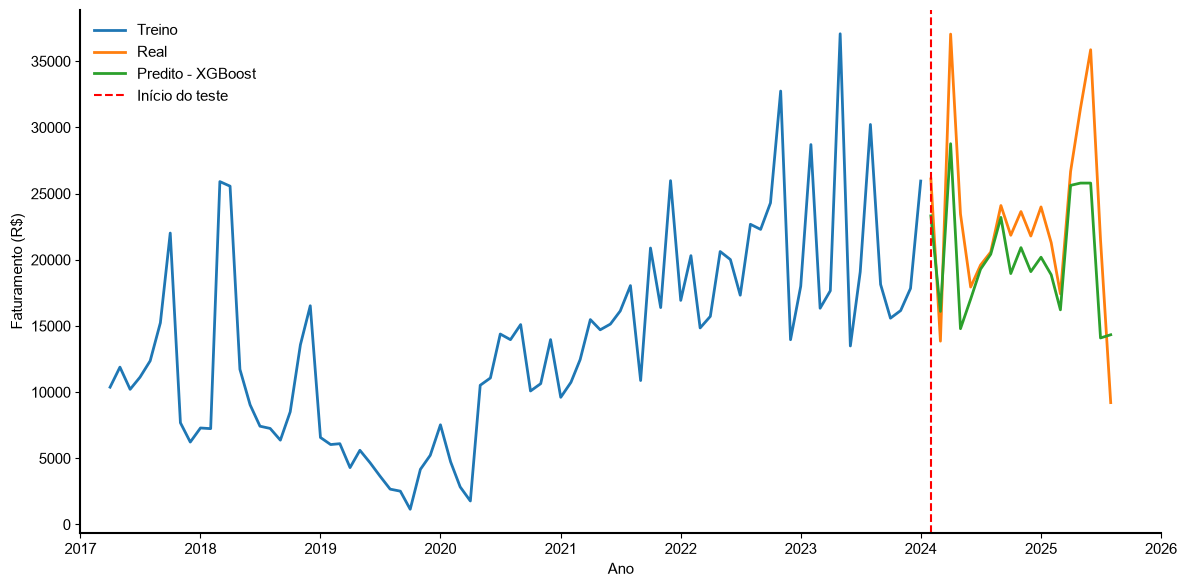

In [158]:
plot_with_style(
    grafico_xgb_02,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=grafico_xgb_02.index[split],
    vline_label='start of the test'
)

## 03 - dynamics of growth:

$g_{t} = \frac{y_{t-1}}{y_{t-2}} - 1$

In [ ]:
df_03 = df_naive.copy()

def safe_growth(numerator, denominator):
    return np.where(
        denominator != 0,
        numerator / denominator - 1,
        np.nan
    )

prev_1 = df_03['valor_total'].shift(1)
prev_2 = df_03['valor_total'].shift(2)

df_03['growth_1'] = safe_growth(
    prev_1,
    prev_2
)

df_03.dropna(inplace=True)

df_03.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1,growth_1
3,2017,5,11889.0,702.0,10374.0,-0.623353
4,2017,6,10213.0,493.0,11889.0,0.146038
5,2017,7,11127.0,627.0,10213.0,-0.140971
6,2017,8,12364.0,436.0,11127.0,0.089494
7,2017,9,15239.0,869.0,12364.0,0.111171


In [ ]:
X = df_03.drop(columns=['quantidade_total', 'valor_total', 'faturamento_lag1'])
y = df_03['valor_total']

X.head()

,ano,mes,growth_1
3,2017,5,-0.623353
4,2017,6,0.146038
5,2017,7,-0.140971
6,2017,8,0.089494
7,2017,9,0.111171


In [ ]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [ ]:
xgb_03 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_03.fit(X_train, y_train)

y_pred_xgb_03 = xgb_03.predict(X_test)

In [ ]:
mae_xgb_03 = mean_absolute_error(y_test, y_pred_xgb_03)

rmse_xgb_03 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_03)
)

print(f'MAE - XGBoost 03: {mae_xgb_03:.2f}')
print(f'RMSE - XGBoost 03: {rmse_xgb_03:.2f}')

MAE - XGBoost 03: 5751.73
RMSE - XGBoost 03: 7571.77


here can-if notice that the indíce of growth piora the model, or whether, the model if adequa more a mudanças rápidas with difference of dois months; vale a pena tentar understand a difference entre more months also influencia, analyzing different *lags*

is interesting note that, combinando the variables `revenue_lag1` and `growth1` the model has a piora, with MAE = 6767.49 and RMSE = 8277.42, mas only with a variable `growth1` has-if MAE = 5751.73 and RMSE = 7571.77, logo increase a complexidade of the model parece piorá-lo.

## 04 - XGBoost with seasonality: trimestral, semestral and annual

In [ ]:
df_04 = df_naive.copy()

for lag in [1, 2, 3, 6, 12]:
    df_04[f'lag_{lag}'] = (
        df_04['valor_total'].shift(lag)
    )
df_04.dropna(inplace=True)

df_04.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1,lag_1,lag_2,lag_3,lag_6,lag_12
13,2018,3,25907.0,1357.0,7242.0,7242.0,7292.0,6228.0,15239.0,27543.0
14,2018,4,25562.0,1008.0,25907.0,25907.0,7242.0,7292.0,22019.0,10374.0
15,2018,5,11724.0,1021.0,25562.0,25562.0,25907.0,7242.0,7685.0,11889.0
16,2018,6,9040.0,573.0,11724.0,11724.0,25562.0,25907.0,6228.0,10213.0
17,2018,7,7427.0,425.0,9040.0,9040.0,11724.0,25562.0,7292.0,11127.0


In [ ]:
X = df_04.drop(columns=['quantidade_total', 'valor_total', 'faturamento_lag1', 'lag_2', 'lag_3'])
y = df_04['valor_total']

X.head()

,ano,mes,lag_1,lag_6,lag_12
13,2018,3,7242.0,15239.0,27543.0
14,2018,4,25907.0,22019.0,10374.0
15,2018,5,25562.0,7685.0,11889.0
16,2018,6,11724.0,6228.0,10213.0
17,2018,7,9040.0,7292.0,11127.0


In [ ]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [ ]:
xgb_04 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_04.fit(X_train, y_train)

y_pred_xgb_04 = xgb_04.predict(X_test)

In [ ]:
mae_xgb_04 = mean_absolute_error(y_test, y_pred_xgb_04)

rmse_xgb_04 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_04)
)

print(f'MAE - XGBoost 04: {mae_xgb_04:.2f}')
print(f'RMSE - XGBoost 04: {rmse_xgb_04:.2f}')

MAE - XGBoost 04: 6039.04
RMSE - XGBoost 04: 8324.08


1) Lag1 + Lag2 + Lag3 + Lag6 + Lag12: MAE = 6264.24 and RMSE = 8715.89
2) Lag1 + Lag2: MAE = 7106.54 and RMSE = 8767.35
3) Lag1 + Lag2 + Lag3: MAE = 7538.82 and RMSE = 10212.30
4) Lag1 + Lag6: MAE = 7666.01 and RMSE = 9776.91
5) Lag1 + Lag12: MAE = 6278.31 and RMSE = 8869.35
6) Lag1 + Lag6 + Lag12: MAE = 6039.04 and RMSE 8324.08

a partir desse experimento, can-if notice that the model XGBoost mostrou that not there are the capturar seasonality for a forecasting of the model.

## 05 - combination of the Lag1, growth1 and diff1

* Este model tentará capturar the variáções rápidas of the série temporal

In [ ]:
df_05 = df_03.copy()

df_05['diff1'] = df_05['valor_total'].diff(1)
df_05.dropna(inplace=True)  # Remover a first linha with NaN

df_05.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1,growth_1,diff1
4,2017,6,10213.0,493.0,11889.0,0.146038,-1676.0
5,2017,7,11127.0,627.0,10213.0,-0.140971,914.0
6,2017,8,12364.0,436.0,11127.0,0.089494,1237.0
7,2017,9,15239.0,869.0,12364.0,0.111171,2875.0
8,2017,10,22019.0,756.0,15239.0,0.232530,6780.0


In [ ]:
X = df_05.drop(columns=['quantidade_total', 'valor_total'])
y = df_05['valor_total']

X.head()

,ano,mes,faturamento_lag1,growth_1,diff1
4,2017,6,11889.0,0.146038,-1676.0
5,2017,7,10213.0,-0.140971,914.0
6,2017,8,11127.0,0.089494,1237.0
7,2017,9,12364.0,0.111171,2875.0
8,2017,10,15239.0,0.232530,6780.0


In [ ]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [ ]:
xgb_05 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_05.fit(X_train, y_train)

y_pred_xgb_05 = xgb_05.predict(X_test)

In [ ]:
mae_xgb_05 = mean_absolute_error(y_test, y_pred_xgb_05)

rmse_xgb_05 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_05)
)

print(f'MAE - XGBoost 05: {mae_xgb_05:.2f}')
print(f'RMSE - XGBoost 05: {rmse_xgb_05:.2f}')

MAE - XGBoost 05: 4011.53
RMSE - XGBoost 05: 5029.34


a partir deste result, we notice that the model tende a prever better with variations temporais rápidas, with até 1 month of period of difference. a inserção of the variable `growth1` of growth. 

therefore, até here, the better model is the 02 with only the uso of the *lag1* and *diff1*.

## 06 - Entendendo the papel of the variable `quantity`

In [ ]:
df_06 = df_naive.copy()

df_06['quantidade_lag1'] = df_06['quantidade_total'].shift(5)
df_06.dropna(inplace=True)  # Remover a first linha with NaN

df_06.head()

,ano,mes,valor_total,quantidade_total,faturamento_lag1,quantidade_lag1
6,2017,8,12364.0,436.0,11127.0,1030.0
7,2017,9,15239.0,869.0,12364.0,577.0
8,2017,10,22019.0,756.0,15239.0,702.0
9,2017,11,7685.0,405.0,22019.0,493.0
10,2017,12,6228.0,423.0,7685.0,627.0


In [ ]:
X = df_06.drop(columns=['quantidade_total', 'valor_total'])
y = df_06['valor_total']

X.head()

,ano,mes,faturamento_lag1,quantidade_lag1
6,2017,8,11127.0,1030.0
7,2017,9,12364.0,577.0
8,2017,10,15239.0,702.0
9,2017,11,22019.0,493.0
10,2017,12,7685.0,627.0


In [ ]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [ ]:
xgb_06 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_06.fit(X_train, y_train)

y_pred_xgb_06 = xgb_06.predict(X_test)

In [ ]:
mae_xgb_06 = mean_absolute_error(y_test, y_pred_xgb_06)

rmse_xgb_06 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_06)
)

print(f'MAE - XGBoost Faturamento e Quantidade Lag1: {mae_xgb_06:.2f}')
print(f'RMSE - XGBoost Faturamento e Quantidade Lag1: {rmse_xgb_06:.2f}')

MAE - XGBoost Faturamento e Quantidade Lag1: 7103.05
RMSE - XGBoost Faturamento e Quantidade Lag1: 9183.77


## 07 - understanding a application of price and quantity

In [ ]:
df['valor_ponderado'] = (
    df['valor_unitario'] * df['quantidade']
)

df_07 = (
    df.groupby(['ano', 'mes'])
      .agg(
        valor_total=('valor_total', 'sum'),
        quantidade_total=('quantidade', 'sum'),
        valor_ponderado=('valor_ponderado', 'sum')
      )
      .reset_index()
)

df_07['preco_medio'] = (
    df_07['valor_ponderado'] / df_07['quantidade_total']
)

df_07['quantidade_lag1'] = df_07['quantidade_total'].shift(1)
df_07['preco_medio_lag1'] = df_07['preco_medio'].shift(1)
df_07['faturamento_lag1'] = df_07['valor_total'].shift(1)

df_07.dropna(inplace=True)  # Remover a first linha with NaN
df_07.head()

,ano,mes,valor_total,quantidade_total,valor_ponderado,preco_medio,quantidade_lag1,preco_medio_lag1,faturamento_lag1
1,2017,3,27543.0,1030.0,27543.0,26.740777,252.0,21.638889,5453.0
2,2017,4,10374.0,577.0,10374.0,17.979203,1030.0,26.740777,27543.0
3,2017,5,11889.0,702.0,11889.0,16.935897,577.0,17.979203,10374.0
4,2017,6,10213.0,493.0,10213.0,20.716024,702.0,16.935897,11889.0
5,2017,7,11127.0,627.0,11127.0,17.746411,493.0,20.716024,10213.0


In [ ]:
X = df_07.drop(columns=['valor_total', 'valor_ponderado', 'preco_medio', 'quantidade_total'])
y = df_07['valor_total']
X.head()

,ano,mes,quantidade_lag1,preco_medio_lag1,faturamento_lag1
1,2017,3,252.0,21.638889,5453.0
2,2017,4,1030.0,26.740777,27543.0
3,2017,5,577.0,17.979203,10374.0
4,2017,6,702.0,16.935897,11889.0
5,2017,7,493.0,20.716024,10213.0


In [ ]:
X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [ ]:
xgb_07 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'  # Adicionado for evitar aviso of depreciação
)

xgb_07.fit(X_train, y_train)

y_pred_xgb_07 = xgb_07.predict(X_test)

In [ ]:
mae_xgb_07 = mean_absolute_error(y_test, y_pred_xgb_07)

rmse_xgb_07 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_07)
)

print(f'MAE - XGBoost 07 (faturamento/quantidade/preço médio lag1): {mae_xgb_07:.2f}')
print(f'RMSE - XGBoost 07 (faturamento/quantidade/preço médio lag1): {rmse_xgb_07:.2f}')

MAE - XGBoost 07 (faturamento/quantidade/preço médio lag1): 6136.07
RMSE - XGBoost 07 (faturamento/quantidade/preço médio lag1): 8555.02
